<h1 style="text-align: center;">Simulación y Aplicaciones en Ciencias Sociales y Experimentales
</h3>
<h3 style="text-align: center;"> Prueba final </h3>
<h3 style="text-align: center;"> 20/12/2024 </h3>

## Ejercicio 1 

Supóngase la existencia de una plaga de insectos que afecta a un cultivo agrícola. El propósito de este ejercicio es, a través de la simulación, encontrar la vía más eficaz y menos costosa de controlar la plaga. 

**(a)** Se dispone del siguiente registro de la población de insectos (en miles) a lo largo de unos días:

In [1]:
días = [0, 5, 7, 15, 16, 25, 29, 30, 31, 44, 47, 50]
población = [0.1, 0.5, 1.5, 5.9, 9.1, 10.5, 12.3, 12.35, 11.9, 12.45, 12.63, 12.51]

Se trata de encontrar el modelo de crecimiento que mejor se ajuste a los registros. Elegir uno de los tres siguientes: 
$$\hbox{Von Bertalanffy: } \frac{dx}{dt} = a x^{2/3} - b x, $$
$$\hbox{Logístico: } \frac{dx}{dt} = a x - b x^2, $$
$$\hbox{Gompertz: } \frac{dx}{dt} = a x - b x \log(x), $$

donde $x(t)$ es el número de insectos o tamaño de la población, $a$ y $b$ dos parámetros. Ajustar los parámetros $a$ y $b$ a los datos. Indicar el error cometido en el ajuste (MAE ó RMSE) (Recomendación: en el ajuste del modelo usar como valores de partida de los parámetros $a=0.5$ y $b=0.005$). 

**(b)** El modelo parte de la población en el día 50 de los registros anteriores. En esa situación, para controlar la plaga, el granjero fumiga la población con una determinada intensidad o esfuerzo $E$, con $0 \leq E \leq 1$, y que representa el porcentaje de la población que es eliminada cada día con la fumigación. Escribir la ecuación de crecimiento elegida anteriormente incluyendo el efecto de la fumigación. Simular el modelo para distintos valores de $E$. 

**(c)** La plaga daña el cultivo y supone un coste diario de $c_x=3$ por cada millar de insectos. Por otro lado, el insecticida tiene un coste $c_E=100$ por eliminar el 100% de la plaga en un día.  Encontrar el esfuerzo $E^*$ que minimiza el coste total de la empresa (coste de la plaga más el coste de la fumigación). 

**(d)** Alternativamente, la empresa puede comprar una cantidad de depredadores de los insectos, reduciendo su población. Ampliar el modelo del apartado 1 incluyendo el efecto del depredador y la dinámica de la población del depredador. Partir del caso del modelo de Lotka Volterra, donde $x_1$ y $x_2$ representan la población de la presa y depredador, respectivamente: 
$$\frac{dx_1}{dt} = rx_1-dx_1x_2,\\ \frac{dx_2}{dt} = hx_1x_2-mx_2,$$
donde $d=0.01$, $h=0.08$ y $m=0.3$. De estas ecuaciones, la componente de crecimiento natural de la presa se sustituye por el modelo del apartado 1. Si el coste por unidad (en miles) del depredador es $c_d=100$, analizar qué vía (adquirir depredadores o fumigar) es la que reduce el coste total al mínimo. 

**(e)** Estimar el punto de equilibrio del modelo del Apartado 4 a través de la simulación o analíticamente. Analizar a través de la matriz jacobiana qué carácter tiene el punto de equilibrio (estable o inestable).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Método de Euler para 1 variable de estado (escalar)
def solveODE_euler(f, x0, t, arg=()):
    n = len(t)
    x = np.zeros(n)
    x[0] = x0
    for i in range(n - 1):
        x[i+1] = x[i] + (t[i+1] - t[i]) * f(x[i], t[i], *arg)
    return x

# Método de Euler para sistemas de múltiples variables (vectorial)
def solveODE_euler_sys(f, x0, t, arg=()):
    n = len(t)
    x = np.zeros((n, len(x0)))
    x[0] = x0
    for i in range(n - 1):
        x[i+1] = x[i] + (t[i+1] - t[i]) * f(x[i], t[i], *arg)
    return x

# Método de Runge-Kutta de orden 4 para sistemas (más preciso que Euler en sistemas oscilantes)
def solveODE_rk4_sys(f, x0, t, arg=()):
    n = len(t)
    x = np.zeros((n, len(x0)))
    x[0] = x0
    for i in range(n - 1):
        h = t[i+1] - t[i]
        k1 = f(x[i], t[i], *arg)
        k2 = f(x[i] + h/2 * k1, t[i] + h/2, *arg)
        k3 = f(x[i] + h/2 * k2, t[i] + h/2, *arg)
        k4 = f(x[i] + h * k3, t[i] + h, *arg)
        x[i+1] = x[i] + h/6 * (k1 + 2*k2 + 2*k3 + k4)
    return x


Von Bertalanffy  -> a = 0.6917, b = 0.2921 | RMSE = 0.8416 | MAE = 0.6865
Logístico        -> a = 0.3419, b = 0.0281 | RMSE = 0.6584 | MAE = 0.4858
Gompertz         -> a = 0.3585, b = 0.1407 | RMSE = 0.6508 | MAE = 0.4939


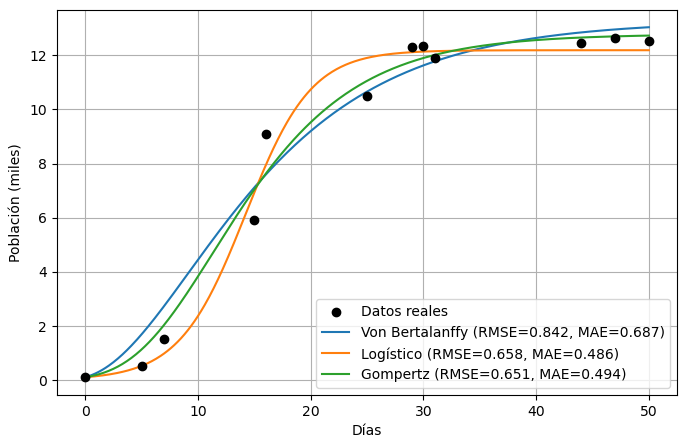

In [3]:
# Apartado A

dias = np.array(días)
poblacion = np.array(población)

# Malla temporal diaria (paso de integración pequeño para evitar inestabilidad numérica)
dt = 0.1
t_ajuste = np.linspace(0, 50, int(50/dt) + 1)
indices_dias = np.round(dias / dt).astype(int)

# Definición de los tres modelos candidatos
def f_bertalanffy(x, t, a, b):
    return a * (max(x, 0)**(2/3)) - b * x

def f_logistico(x, t, a, b):
    return a * x - b * (x**2)

def f_gompertz(x, t, a, b):
    return a * x - b * x * np.log(max(x, 1e-8))

# Función de coste (RMSE) para el optimizador
def loss_rmse(params, f_model):
    a, b = params
    x_sim = solveODE_euler(f_model, poblacion[0], t_ajuste, arg=(a, b))
    x_pred = x_sim[indices_dias]
    return np.sqrt(np.mean((poblacion - x_pred)**2))

# Ajuste con valores iniciales recomendados: a=0.5, b=0.005
p0 = [0.5, 0.005]
modelos = {'Von Bertalanffy': f_bertalanffy, 'Logístico': f_logistico, 'Gompertz': f_gompertz}
resultados = {}

plt.figure(figsize=(8, 5))
plt.scatter(dias, poblacion, color='black', label='Datos reales', zorder=5)

for nombre, f_mod in modelos.items():
    res = minimize(loss_rmse, p0, args=(f_mod,), method='Nelder-Mead')
    a_opt, b_opt = res.x
    x_sim = solveODE_euler(f_mod, poblacion[0], t_ajuste, arg=(a_opt, b_opt))
    x_pred = x_sim[indices_dias]
    
    rmse = np.sqrt(np.mean((poblacion - x_pred)**2))
    mae = np.mean(np.abs(poblacion - x_pred))
    resultados[nombre] = (a_opt, b_opt, rmse, mae)
    
    plt.plot(t_ajuste, x_sim, label=f"{nombre} (RMSE={rmse:.3f}, MAE={mae:.3f})")
    print(f"{nombre:16s} -> a = {a_opt:.4f}, b = {b_opt:.4f} | RMSE = {rmse:.4f} | MAE = {mae:.4f}")

plt.xlabel("Días")
plt.ylabel("Población (miles)")
plt.legend()
plt.grid(True)
plt.show()

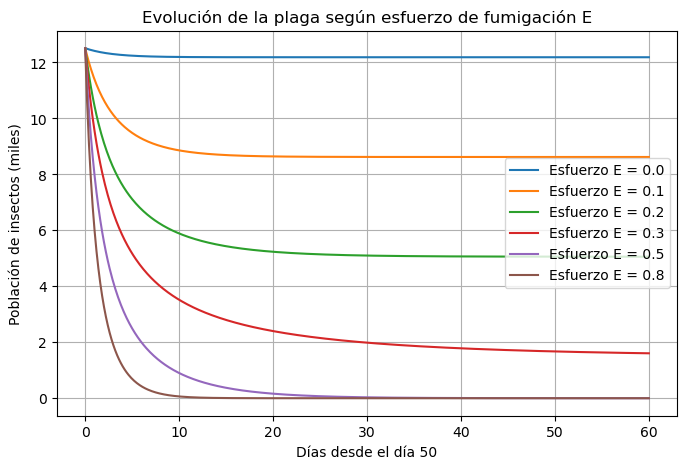

In [4]:
# Apartado B

# Parámetros óptimos del modelo logístico elegido en (a)
a_opt, b_opt = resultados['Logístico'][0], resultados['Logístico'][1]

# Ecuación con esfuerzo de fumigación E (0 <= E <= 1)
def f_fumigacion(x, t, a, b, E):
    dxdt = a * x - b * (x**2) - E * x
    return dxdt

# Condición inicial: población en el día 50
x0_50 = poblacion[-1] # 12.51 miles
t_sim = np.linspace(0, 60, int(60/dt) + 1) # 60 días hacia adelante

plt.figure(figsize=(8, 5))
for E in [0.0, 0.1, 0.2, 0.3, 0.5, 0.8]:
    x_sim = solveODE_euler(f_fumigacion, x0_50, t_sim, arg=(a_opt, b_opt, E))
    plt.plot(t_sim, x_sim, label=f"Esfuerzo E = {E}")

plt.xlabel("Días desde el día 50")
plt.ylabel("Población de insectos (miles)")
plt.title("Evolución de la plaga según esfuerzo de fumigación E")
plt.legend()
plt.grid(True)
plt.show()

Esfuerzo óptimo E* = 0.09 | Coste Total Mínimo = 2194.31
Coste sin fumigar (E = 0): 2200.19


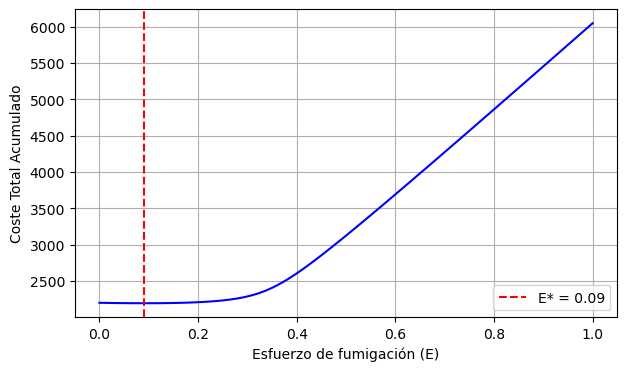

In [5]:
# Apartado C

cx = 3.0    # Coste diario por cada millar de insectos
cE = 100.0  # Coste diario por eliminar el 100% de la plaga (E = 1)
T_horizonte = 60 # Horizonte de evaluación (por ejemplo, 60 días)
t_coste = np.linspace(0, T_horizonte, int(T_horizonte/dt) + 1)

esfuerzos = np.linspace(0, 1, 101)
costes_totales = []

for E in esfuerzos:
    x_sim = solveODE_euler(f_fumigacion, x0_50, t_coste, arg=(a_opt, b_opt, E))
    # Integración del coste diario a lo largo del horizonte temporal: ∫ (cx*x(t) + cE*E) dt
    coste_plaga = np.sum(cx * x_sim * dt)
    coste_fumig = cE * E * T_horizonte   # coste diario cE*E durante T_horizonte días
    costes_totales.append(coste_plaga + coste_fumig)

idx_min = np.argmin(costes_totales)
E_opt = esfuerzos[idx_min]
coste_min_fumig = costes_totales[idx_min]

print(f"Esfuerzo óptimo E* = {E_opt:.2f} | Coste Total Mínimo = {coste_min_fumig:.2f}")
print(f"Coste sin fumigar (E = 0): {costes_totales[0]:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(esfuerzos, costes_totales, 'b-')
plt.axvline(E_opt, color='r', linestyle='--', label=f'E* = {E_opt:.2f}')
plt.xlabel("Esfuerzo de fumigación (E)")
plt.ylabel("Coste Total Acumulado")
plt.legend()
plt.grid(True)
plt.show()

Depredadores óptimos x2(0)* = 0.40 | Coste Total Mínimo (Depredadores) = 878.11
Comparación -> Coste Fumigación: 2194.31 vs Coste Depredadores: 878.11
Vía más económica: adquirir depredadores


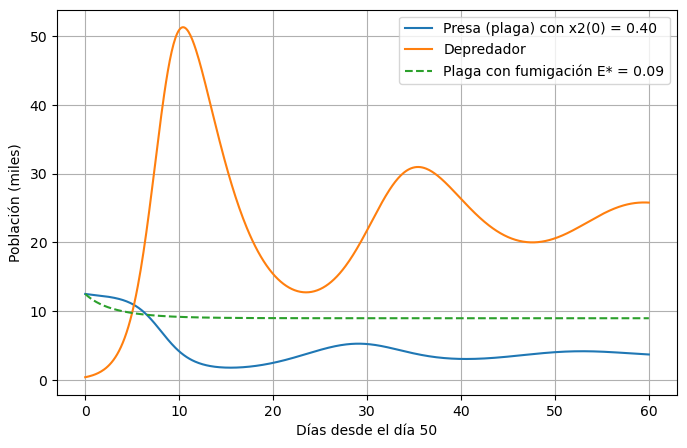

In [6]:
# Apartado D

d = 0.01
h = 0.08
m = 0.3
cd = 100.0 # Coste por unidad (en miles) de depredador comprada inicialmente

# Sistema acoplado: x[0] = x1 (presa/plaga), x[1] = x2 (depredador)
def f_depredador(x, t, a, b, d, h, m):
    x1, x2 = x[0], x[1]
    dx1dt = (a * x1 - b * (x1**2)) - d * x1 * x2
    dx2dt = h * x1 * x2 - m * x2
    return np.array([dx1dt, dx2dt])

# Búsqueda de la cantidad inicial de depredadores x2(0) que minimiza el coste
depredadores_ini = np.linspace(0, 30, 301)   # incluye x2(0)=0 (no comprar)
costes_depredador = []

for x2_0 in depredadores_ini:
    x_init = np.array([x0_50, x2_0])
    sol = solveODE_euler_sys(f_depredador, x_init, t_coste, arg=(a_opt, b_opt, d, h, m))
    x1_sim = sol[:, 0]
    
    # Coste del daño de la plaga + compra inicial de depredadores
    coste_plaga = np.sum(cx * x1_sim * dt)
    coste_compra = cd * x2_0
    costes_depredador.append(coste_plaga + coste_compra)

idx_min_dep = np.argmin(costes_depredador)
x2_opt = depredadores_ini[idx_min_dep]
coste_min_dep = costes_depredador[idx_min_dep]

print(f"Depredadores óptimos x2(0)* = {x2_opt:.2f} | Coste Total Mínimo (Depredadores) = {coste_min_dep:.2f}")
print(f"Comparación -> Coste Fumigación: {coste_min_fumig:.2f} vs Coste Depredadores: {coste_min_dep:.2f}")
mejor = "adquirir depredadores" if coste_min_dep < coste_min_fumig else "fumigar"
print(f"Vía más económica: {mejor}")

# Evolución con la cantidad óptima de depredadores
sol_opt = solveODE_euler_sys(f_depredador, np.array([x0_50, x2_opt]), t_coste, arg=(a_opt, b_opt, d, h, m))
x_fum_opt = solveODE_euler(f_fumigacion, x0_50, t_coste, arg=(a_opt, b_opt, E_opt))
plt.figure(figsize=(8, 5))
plt.plot(t_coste, sol_opt[:, 0], label=f"Presa (plaga) con x2(0) = {x2_opt:.2f}")
plt.plot(t_coste, sol_opt[:, 1], label="Depredador")
plt.plot(t_coste, x_fum_opt, '--', label=f"Plaga con fumigación E* = {E_opt:.2f}")
plt.xlabel("Días desde el día 50")
plt.ylabel("Población (miles)")
plt.legend()
plt.grid(True)
plt.show()


In [7]:
# Apartado E

# 1. Cálculo analítico del punto de equilibrio interior (x1* > 0, x2* > 0)
# De dx2/dt = 0 -> h*x1 - m = 0  ==> x1* = m / h
x1_eq = m / h
# De dx1/dt = 0 -> a - b*x1 - d*x2 = 0 ==> x2* = (a - b*x1*) / d
x2_eq = (a_opt - b_opt * x1_eq) / d

print(f"Punto de equilibrio interior: x1* = {x1_eq:.4f}, x2* = {x2_eq:.4f}")

# 2. Construcción de la Matriz Jacobiana evaluada en (x1*, x2*)
J11 = a_opt - 2 * b_opt * x1_eq - d * x2_eq
J12 = -d * x1_eq
J21 = h * x2_eq
J22 = h * x1_eq - m

J = np.array([[J11, J12],
              [J21, J22]])

autovalores = np.linalg.eigvals(J)
print("Matriz Jacobiana en el equilibrio:\n", J)
print("Valores propios (autovalores):", autovalores)

if np.all(np.real(autovalores) < 0):
    tipo = "foco estable" if np.any(np.imag(autovalores) != 0) else "nodo estable"
else:
    tipo = "inestable"
print(f"Carácter del equilibrio interior: {tipo}")

# Equilibrios de frontera: (0,0) y (a/b, 0)
def jac(x1, x2):
    return np.array([[a_opt - 2*b_opt*x1 - d*x2, -d*x1],
                     [h*x2, h*x1 - m]])
for pe in [(0.0, 0.0), (a_opt/b_opt, 0.0)]:
    print(f"Equilibrio ({pe[0]:.3f}, {pe[1]:.3f}) -> autovalores {np.linalg.eigvals(jac(*pe))}")


Punto de equilibrio interior: x1* = 3.7500, x2* = 23.6684
Matriz Jacobiana en el equilibrio:
 [[-0.1051935  -0.0375    ]
 [ 1.89347259  0.        ]]
Valores propios (autovalores): [-0.05259675+0.26122558j -0.05259675-0.26122558j]
Carácter del equilibrio interior: foco estable
Equilibrio (0.000, 0.000) -> autovalores [ 0.34187757 -0.3       ]
Equilibrio (12.187, 0.000) -> autovalores [-0.34187757  0.67499629]


## Ejercicio 2

El oscilador de Van der Pol es un sistema dinámico creado alrededor de 1926 que consiste en un circuito eléctrico con realimentaciones positivas y resistores no lineales. El circuito, tal como se diseñó, favorece oscilaciones pequeñas y amortigua las grandes. Una extensión de estos sistemas se ha aplicado en Medicina para simular el proceso de un marcapasos. Un interesante resumen de la historia y análisis matemático del oscilador de Van der Pol lo pueden encontrar en el trabajo de [Casaico-Suárez et al. (1920)](https://www.researchgate.net/publication/344507421_El_Oscilador_de_Van_Der_Pol).

Aplicando las leyes físicas al circuito eléctrico de Van der Pol, se llega a la siguiente ecuación:

$$\ddot{x} -\mu (1-x^2) \dot{x} +x =0,$$

donde $x$ es una combinación de las variables eléctricas del sistema (intensidad, voltaje, etc.) y $\mu$ es un parámetro de control de la resistencia.

**a)** Simular el sistema de orden 2 para las condiciones iniciales $x(0)=0.5$, $\dot{x}(0)=0.5$ y $\mu=1$. Para ello escribir el modelo como un sistema de ecuaciones diferenciales de dos variables $x$ e $y$, con $y= \dot{x}$. Realizar la gráfica de la trayectoria de la variable $x$ y el diagrama de fases $(x,y)$.

**b)** Hallar los puntos de equilibrio del sistema y los valores propios del sistema en función de $\mu$. Determinar valores de $\mu$ donde los valores propios cambian de signo y/o la parte imaginaria del valor propio pasa de nula a no nula o viceversa.

**c)** Simular el modelo para valores de $\mu$ dentro de los diversos rangos definidos por los valores calculados en el apartado **b)**. Tomar distintas condiciones iniciales.

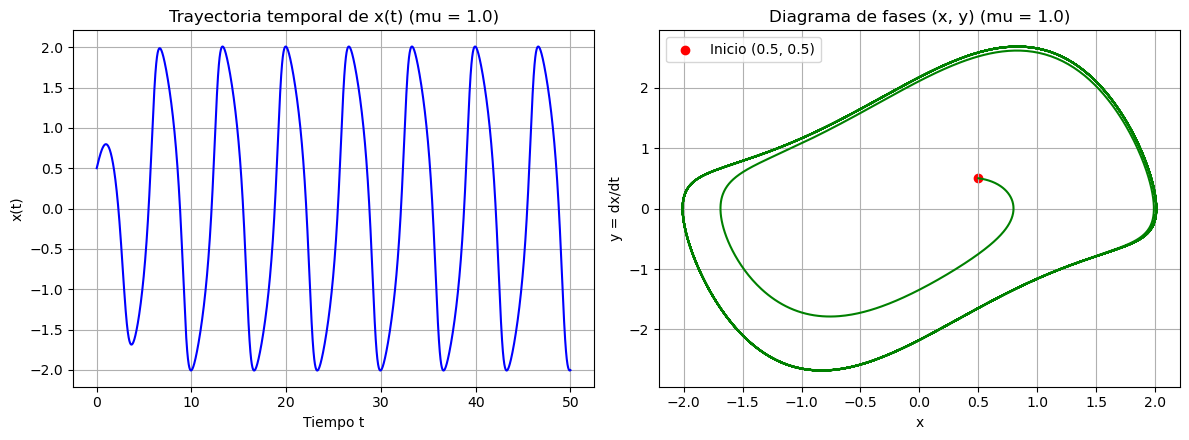

In [8]:
# Apartado A

# Sistema de ecuaciones de primer orden:
# x_vec[0] = x
# x_vec[1] = y = dx/dt
def f_vanderpol(x_vec, t, mu):
    x, y = x_vec[0], x_vec[1]
    dxdt = y
    dydt = mu * (1 - x**2) * y - x
    return np.array([dxdt, dydt])

# Parámetros y condiciones iniciales del apartado (a)
dt_vdp = 0.01
t_vdp = np.linspace(0, 50, int(50/dt_vdp) + 1)
x0_vdp = np.array([0.5, 0.5]) # x(0) = 0.5, x'(0) = 0.5
mu_a = 1.0

sol_vdp = solveODE_rk4_sys(f_vanderpol, x0_vdp, t_vdp, arg=(mu_a,))
x_tray = sol_vdp[:, 0]
y_tray = sol_vdp[:, 1]

# Gráficas: Trayectoria temporal x(t) y Diagrama de fases (x, y)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(t_vdp, x_tray, 'b-')
ax[0].set_title(f"Trayectoria temporal de x(t) (mu = {mu_a})")
ax[0].set_xlabel("Tiempo t")
ax[0].set_ylabel("x(t)")
ax[0].grid(True)

ax[1].plot(x_tray, y_tray, 'g-')
ax[1].scatter(x0_vdp[0], x0_vdp[1], color='red', label='Inicio (0.5, 0.5)')
ax[1].set_title(f"Diagrama de fases (x, y) (mu = {mu_a})")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y = dx/dt")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [9]:
# Apartado B

import sympy as sp

x_s, y_s, mu_s = sp.symbols('x y mu', real=True)
f1 = y_s
f2 = mu_s * (1 - x_s**2) * y_s - x_s

# Puntos de equilibrio
eq_points = sp.solve([f1, f2], (x_s, y_s))
print("Puntos de equilibrio:", eq_points)

# Matriz Jacobiana en el equilibrio (0, 0)
J_sym = sp.Matrix([[f1, f2]]).jacobian([x_s, y_s]).subs({x_s: 0, y_s: 0})
print("Jacobiana en (0,0):", J_sym)
print("Autovalores en función de mu:", J_sym.eigenvals())

Puntos de equilibrio: [(0, 0)]
Jacobiana en (0,0): Matrix([[0, 1], [-1, mu]])
Autovalores en función de mu: {mu/2 - sqrt((mu - 2)*(mu + 2))/2: 1, mu/2 + sqrt((mu - 2)*(mu + 2))/2: 1}


mu = -2.5, x0 = [2. 2.]: la trayectoria diverge (fuera del ciclo límite inestable)
mu = -1.0, x0 = [2. 2.]: la trayectoria diverge (fuera del ciclo límite inestable)


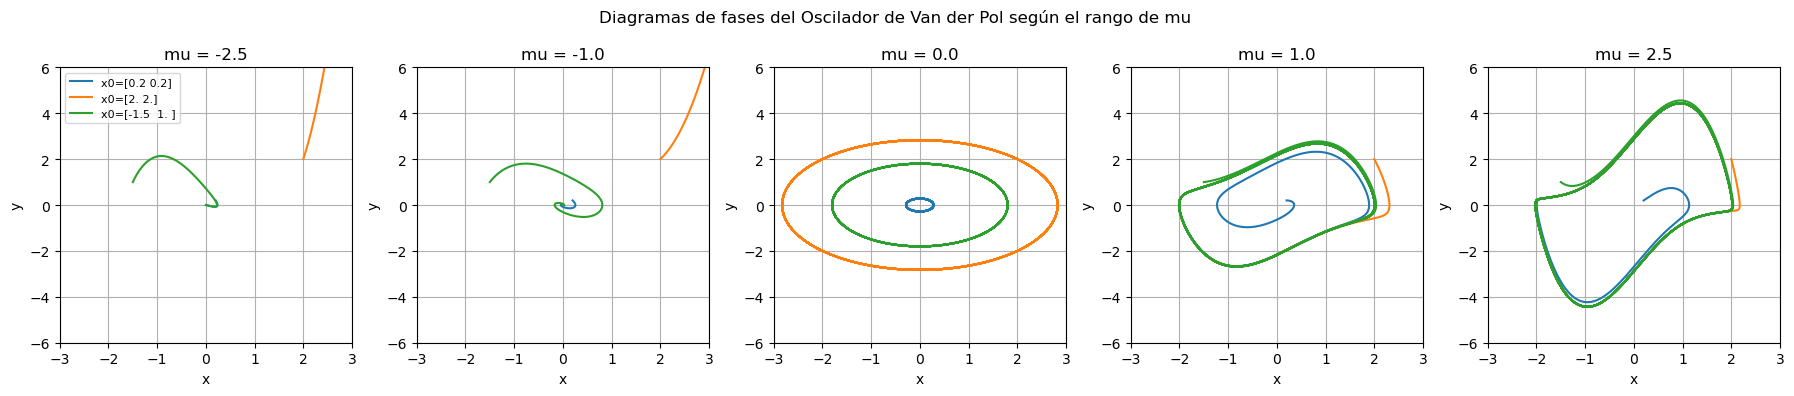

In [10]:
# Apartado C

# Valores representativos de mu en cada rango hallado en (b):
# mu = -2.5 (<-2, nodo estable), mu = -1.0 ((-2,0), foco estable),
# mu = 0.0 (centro), mu = 1.0 ((0,2), foco inestable -> ciclo límite),
# mu = 2.5 (>2, nodo inestable -> ciclo límite de relajación)
valores_mu = [-2.5, -1.0, 0.0, 1.0, 2.5]
condiciones_ini = [np.array([0.2, 0.2]), np.array([2.0, 2.0]), np.array([-1.5, 1.0])]

fig, axes = plt.subplots(1, len(valores_mu), figsize=(18, 4))

for i, mu_val in enumerate(valores_mu):
    for x0_ci in condiciones_ini:
        with np.errstate(over='ignore', invalid='ignore'):   # para mu<0 algunas trayectorias divergen
            sol = solveODE_rk4_sys(f_vanderpol, x0_ci, t_vdp, arg=(mu_val,))
        if not np.all(np.isfinite(sol)):
            print(f"mu = {mu_val}, x0 = {x0_ci}: la trayectoria diverge (fuera del ciclo límite inestable)")
        axes[i].plot(sol[:, 0], sol[:, 1], label=f"x0={x0_ci}")
    
    axes[i].set_title(f"mu = {mu_val}")
    axes[i].set_xlabel("x")
    axes[i].set_ylabel("y")
    axes[i].set_xlim(-3, 3)
    axes[i].set_ylim(-6, 6)
    axes[i].grid(True)
    if i == 0:
        axes[i].legend(fontsize=8)

plt.suptitle("Diagramas de fases del Oscilador de Van der Pol según el rango de mu")
plt.tight_layout()
plt.show()